# Chaos and fractals 2: Fractals

*Learning path: chaos and fractals, part 2 of 2.* [Index](README.md) · Previous: [Chaos](01-chaos.ipynb)

A **fractal** is a shape with detail at every scale: zoom in and there is always more. Coastlines, ferns, lungs and the
Lorenz attractor of lesson 1 are like that. Benoit Mandelbrot gave them their name in 1975. You will learn

* why the Koch snowflake has infinite length but finite area,
* the **fractal dimension**, a number like 1.26 between the dimensions of a line and a plane,
* how the **Mandelbrot set** is computed, and what its pictures show,
* **Julia sets**, and how the Mandelbrot set is a map of all of them.

This lesson uses complex numbers ([foundations lesson 6](../foundations/06-complex-numbers.ipynb)), where the
Mandelbrot set was first introduced, and `iterate` from lesson 1.

## 1. The Koch snowflake

Start with a line segment. Cut it in three, and replace the middle third by two sides of an equilateral triangle
pointing outwards: four segments, each $1/3$ as long. Repeat on every segment, forever. Three such curves around a
triangle make the **Koch snowflake** (Helge von Koch, 1904).

Each step multiplies the number of segments by 4 and their length by $1/3$, so the total length is multiplied by $4/3$.
The table lists the step $n$, the number of segments $4^n$, and the length $(4/3)^n$ of a curve that started with
length 1:

In [1]:
table([n, 4^n, (4/3)^n, eval((4/3)^n)], n, 0, 10)
limit((4/3)^n, n, inf)

[ 0,       1,             1,                1.0;
  1,       4,           4/3, 1.3333333333333333;
  2,      16,          16/9, 1.7777777777777777;
  3,      64,         64/27, 2.3703703703703702;
  4,     256,        256/81, 3.1604938271604937;
  5,    1024,      1024/243, 4.2139917695473255;
  6,    4096,      4096/729,  5.618655692729766;
  7,   16384,    16384/2187,  7.491540923639689;
  8,   65536,    65536/6561,  9.988721231519586;
  9,  262144,  262144/19683, 13.318294975359446;
 10, 1048576, 1048576/59049, 17.757726633812595]

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

inf

> `limit`: Limit of f as x approaches a, from both sides or one side.

The length grows without bound. The area, on the other hand, converges: at step $n$ the snowflake gains $3\cdot4^{n-1}$
small triangles, each $1/9$ the area of those of the step before. Starting from a triangle of area 1, the total is a
geometric series (`sum` with `inf` as upper limit adds infinitely many terms):

In [2]:
1 + sum(3*4^(n - 1)/9^n, n, 1, inf)

8/5

An infinitely long curve around a finite area of $8/5$ of the starting triangle. A coastline behaves the same way:
the finer the ruler, the longer the measured coast (Lewis Fry Richardson noticed this for the border between Spain and
Portugal, which the two countries measured differently).

## 2. Fractal dimension

Scale a line segment by $1/3$ and you need 3 copies to rebuild it; a square needs $9 = 3^2$, a cube $27 = 3^3$. The
exponent is the dimension: $N = (1/s)^D$ copies at scale $s$, so

$$D = \frac{\log N}{\log(1/s)}.$$

The Koch curve is made of $N = 4$ copies at scale $s = 1/3$. The Sierpinski triangle (cut the middle quarter out of a
triangle, repeat on the three corners) has 3 copies at scale $1/2$; the Cantor set (remove middle thirds of a segment)
has 2 copies at scale $1/3$:

In [3]:
eval(log(4)/log(3))
eval(log(3)/log(2))
eval(log(2)/log(3))

1.2618595071429146

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

1.5849625007211563

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.6309297535714573

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The Koch curve is more than a line but less than a surface: $D \approx 1.26$. The Sierpinski triangle has
$D \approx 1.58$, the Cantor set $D \approx 0.63$ (more than a scattering of points, less than a line). The coast of
Britain has $D \approx 1.25$, almost the Koch value.

## 3. The Mandelbrot set

Pick a complex number $c$ and iterate $z \to z^2 + c$ starting from $z = 0$, as in foundations lesson 6. Either the
values stay bounded, or they run off to infinity (once $|z| > 2$ they always do). The **Mandelbrot set** is the set of
$c$ for which they stay bounded:

In [4]:
abs(iterate(z^2 + (-1), z, 0, 8))
abs(iterate(z^2 + (0.5), z, 0, 8))

[0, 1, 0, 1, 0, 1, 0, 1, 0]

> `abs`: Absolute value; for a complex number a + b*i the modulus sqrt(a^2 + b^2).

[0, 0.5, 0.75, 1.0625, 1.62890625, 3.1533355712890625, 10.44352522515691816806793212890625, 109.56721912848886, 12005.475507550294]

> `abs`: Absolute value; for a complex number a + b*i the modulus sqrt(a^2 + b^2).

$c = -1$ cycles $0, -1, 0, -1, \ldots$: it is in the set. $c = 0.5$ escapes: it is not.

To draw the set, test every point of a grid. `mandelbrot(re0, re1, im0, im1, n)` does this for the rectangle of complex
numbers with real part from `re0` to `re1` and imaginary part from `im0` to `im1`, using a grid that is `n` points wide
(and as many high as keeps the squares square). A point counts as inside when $|z| \le 2$ for 200 steps. The result is a
table with one row $[\text{real part},\ \text{imaginary part}]$ per point inside, ready for `scatter`; across is the
real part of $c$, up the imaginary part:

[5517, 2]

> `size` (see `trace`): Sum of the diagonal entries; size gives [rows columns].

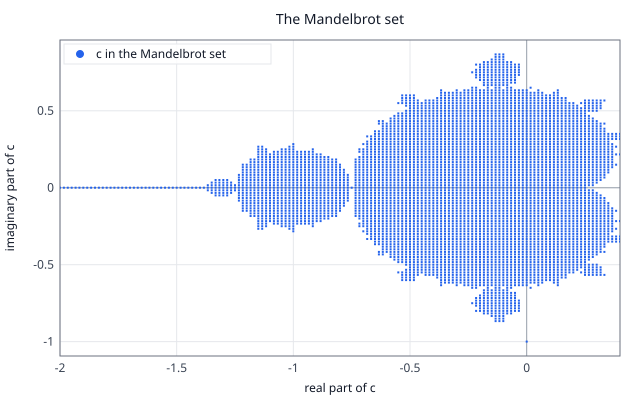

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
M = mandelbrot(-2.2, 0.8, -1.2, 1.2, 180);
size(M)
labels(title(legend(scatter(M, [re im]), "c in the Mandelbrot set"), "The Mandelbrot set"), "real part of c", "imaginary part of c")

The big **cardioid** (heart shape) on the right holds the $c$ for which $z$ settles to a fixed point; the disc on its
left, centred at $-1$, those for which it settles into a cycle of period 2 (like $c = -1$). Smaller discs hold periods
3, 4, 5, ... On the real axis this is exactly the period doubling of the logistic map from lesson 1: the logistic map
and $z \to z^2 + c$ are the same map after a change of variables, with $c = r/2 - r^2/4$.

In [6]:
r = 3.2;
eval(r/2 - r^2/4)

-0.96

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

($r = 3.2$, period 2 in lesson 1, corresponds to $c = -0.96$, inside the period-2 disc.)

### Zooming in

The boundary has detail at every scale. Zooming in at the far left, around $c = -1.75$ on the real axis, the window
from $-1.8$ to $-1.7$ (a hundred times smaller than the whole picture) shows a **small copy of the whole set**:

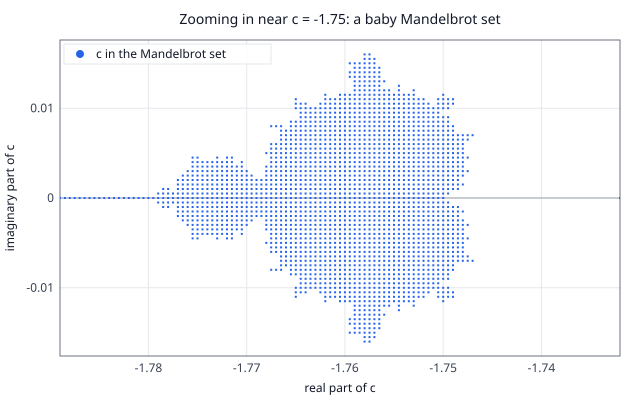

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
Z = mandelbrot(-1.8, -1.7, -0.03, 0.03, 200);
labels(title(legend(scatter(Z, [re im]), "c in the Mandelbrot set"), "Zooming in near c = -1.75: a baby Mandelbrot set"), "real part of c", "imaginary part of c")

This little copy is where the period-3 window of the bifurcation diagram in lesson 1 comes from. The boundary of the
Mandelbrot set has fractal dimension exactly 2 (Mitsuhiro Shishikura, 1998): it is as wiggly as a curve can be.

## 4. Julia sets

Now fix $c$ and vary the *starting point* $z_0$ instead: the **Julia set** of $c$ (Gaston Julia, 1918) is the set of
starting points whose orbit under $z \to z^2 + c$ stays bounded (strictly, its boundary). `julia(c, re0, re1, im0, im1, n)`
draws it like `mandelbrot`, with across the real part and up the imaginary part of $z_0$. Two famous examples:
$c = -1$, the "basilica", and $c = -0.123 + 0.745i$, "Douady's rabbit":

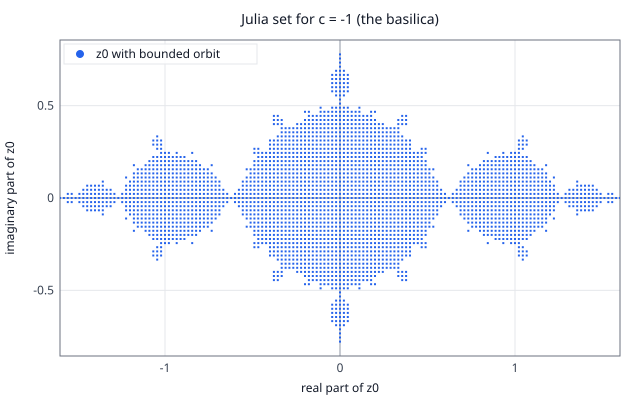

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [8]:
J1 = julia(-1, -2, 2, -1.2, 1.2, 180);
labels(title(legend(scatter(J1, [re im]), "z0 with bounded orbit"), "Julia set for c = -1 (the basilica)"), "real part of z0", "imaginary part of z0")

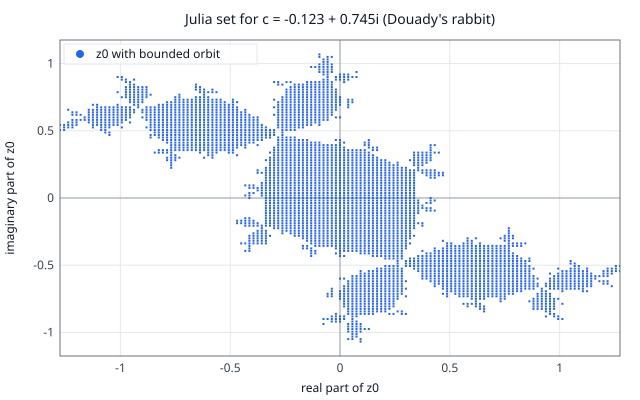

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [9]:
J2 = julia(-0.123 + 0.745*i, -1.5, 1.5, -1.5, 1.5, 160);
labels(title(legend(scatter(J2, [re im]), "z0 with bounded orbit"), "Julia set for c = -0.123 + 0.745i (Douady's rabbit)"), "real part of z0", "imaginary part of z0")

Both $c$ values lie inside the Mandelbrot set, and both Julia sets are connected (one piece). For $c$ outside the
Mandelbrot set the Julia set falls apart into dust, infinitely many separate points: that is the definition Mandelbrot
actually started from. So the Mandelbrot set is a map of all Julia sets: inside, connected; outside, dust. The rabbit's
$c$ sits in a period-3 bulb, and its orbit from 0 indeed settles into a cycle of 3 values (the $|z|$ repeat every
three steps):

In [10]:
abs(iterate(z^2 + (-0.123 + 0.745*i), z, 0, 12))

[0, 0.001*sqrt(570154), 0.000026*sqrt(1116822041), 4e-12*sqrt(53881895629655041), 0.7550857696155563, 0.8688923656372454, 0.0009279367111644345, 0.7550857654670206, 0.8688923632630449, 0.0009279270562747614, 0.7550857654690171, 0.8688923632382349, 0.0009279270931878225]

> `abs`: Absolute value; for a complex number a + b*i the modulus sqrt(a^2 + b^2).

## Summary

* Fractals have detail at every scale. The Koch snowflake: infinite length, area $8/5$.
* Fractal dimension $D = \log N/\log(1/s)$: Koch $1.26$, Sierpinski $1.58$, Cantor $0.63$.
* The Mandelbrot set: the $c$ for which $z \to z^2 + c$ from 0 stays bounded (`mandelbrot`). Its bulbs are periodic
  cycles; on the real axis it is the logistic map's bifurcation diagram.
* Julia sets: the starting points that stay bounded for a fixed $c$ (`julia`); connected exactly when $c$ is in the
  Mandelbrot set.

**Try it:** zoom into the Mandelbrot set around $c = -0.75 + 0.1i$ (the "seahorse valley") with a window 0.05 wide.
Draw the Julia sets for $c = -0.8 + 0.156i$ and $c = i$. What is the dimension of a fractal made of 8 copies at scale
$1/3$ (the Sierpinski carpet)?

## Sources

1. B. B. Mandelbrot, *The Fractal Geometry of Nature*, W. H. Freeman (1982).
2. H. von Koch, "Sur une courbe continue sans tangente, obtenue par une construction géométrique élémentaire", *Arkiv för Matematik* 1 (1904) 681–704.
3. G. Julia, "Mémoire sur l'itération des fonctions rationnelles", *J. Math. Pures Appl.* 8 (1918) 47–245.
4. A. Douady and J. H. Hubbard, "Étude dynamique des polynômes complexes", Publications Mathématiques d'Orsay (1984–85).
5. M. Shishikura, "The Hausdorff dimension of the boundary of the Mandelbrot set and Julia sets", *Annals of Mathematics* 147 (1998) 225–267.
6. B. Mandelbrot, "How long is the coast of Britain?", *Science* 156 (1967) 636–638.